# 1. Project Objective

This notebook documents the Phase 1 dataset acquisition, inspection, and EDA workflow for the PV fault dataset. The objective is to understand the raw MATLAB files before any ML model is trained.

# 2. Dataset Source

Source repository: https://github.com/clayton-h-costa/pv_fault_dataset

Files inspected:
- dataset_elec.mat
- dataset_amb.mat

# 3. Imports

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd().resolve()
if not (project_root / 'src').exists():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data.cleaner import load_verified_dataframe

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 140

# 4. Load Dataset

In [2]:
data_dir = Path('..') / 'data' / 'raw' / 'pv_fault_dataset'
elec = data_dir / 'dataset_elec.mat'
amb = data_dir / 'dataset_amb.mat'
print('Electrical file exists:', elec.exists())
print('Ambient file exists:', amb.exists())

df = load_verified_dataframe(elec, amb)
print(df.shape)
df.head()

Electrical file exists: True
Ambient file exists: True


(1373798, 10)


,vdc1,vdc2,idc1,idc2,irradiance,pv_temperature,fault_label,power_string_1_w,power_string_2_w,actual_power_w
0,0.7143,0.5550,0.0608,0.0073,1.3729,2.3816,0,0.043429,0.004052,0.047481
1,0.6944,0.5427,0.0615,0.0064,1.3604,2.3816,0,0.042706,0.003473,0.046179
2,0.7110,0.5583,0.0646,0.0067,1.5118,2.3883,0,0.045931,0.003741,0.049671
3,0.6991,0.5465,0.0628,0.0067,1.5534,2.3920,0,0.043903,0.003662,0.047565
4,0.7035,0.5553,0.0606,0.0076,1.4355,2.3920,0,0.042632,0.004220,0.046852


# 5. Inspect MATLAB Variables

The raw arrays are read directly from MATLAB files to confirm the exact keys, shapes, and dtypes before any transformation.

In [3]:
from scipy.io import loadmat

for mat_file in [elec, amb]:
    data = loadmat(str(mat_file), squeeze_me=False, struct_as_record=False)
    keys = [k for k in data.keys() if not k.startswith('__')]
    print(mat_file.name, keys)
    for key in keys:
        arr = np.asarray(data[key])
        print(key, 'shape=', arr.shape, 'dtype=', arr.dtype)
    print('-' * 80)

dataset_elec.mat ['idc1', 'idc2', 'vdc1', 'vdc2']
idc1 shape= (1, 1373798) dtype= float64
idc2 shape= (1, 1373798) dtype= float64
vdc1 shape= (1, 1373798) dtype= float64
vdc2 shape= (1, 1373798) dtype= float64
--------------------------------------------------------------------------------
dataset_amb.mat ['f_nv', 'irr', 'pvt']
f_nv shape= (1373798, 1) dtype= uint8
irr shape= (1, 1373798) dtype= float64
pvt shape= (1, 1373798) dtype= float64
--------------------------------------------------------------------------------


# 6. Dataset Structure

The dataset exposes voltage and current vectors for two strings, plus irradiance, temperature, and the label. The actual sample length is checked before combining signals.

In [4]:
print('Rows:', len(df))
print('Columns:', list(df.columns))
print('Fault labels:', sorted(df['fault_label'].unique().tolist()))
df.describe(include='all').T

Rows: 1373798
Columns: ['vdc1', 'vdc2', 'idc1', 'idc2', 'irradiance', 'pv_temperature', 'fault_label', 'power_string_1_w', 'power_string_2_w', 'actual_power_w']
Fault labels: [0, 1, 2, 3, 4]


,count,mean,std,min,25%,50%,75%,max
vdc1,1373798.0,135.118273,136.333921,0.379900,0.890700,37.776250,273.060000,363.974000
vdc2,1373798.0,134.719897,136.730871,0.316400,0.884000,39.837450,271.986000,368.749000
idc1,1373798.0,2.276919,3.190345,0.041800,0.068600,0.113600,5.102100,9.654900
idc2,1373798.0,2.000344,3.038147,0.004600,0.012700,0.044100,4.140400,9.498700
irradiance,1373798.0,257.611072,353.121870,-0.038100,1.290100,1.736400,590.718000,1085.920000
pv_temperature,1373798.0,22.772770,14.231485,-1.654300,12.132700,18.490450,34.155950,60.821500
fault_label,1373798.0,0.581385,1.389633,0.000000,0.000000,0.000000,0.000000,4.000000
power_string_1_w,1373798.0,603.927553,859.676079,0.018873,0.072569,3.361390,1409.854771,2495.545529
power_string_2_w,1373798.0,535.500247,815.727047,0.001621,0.019406,0.732297,1129.141446,2473.800600
actual_power_w,1373798.0,1139.427800,1653.561229,0.021521,0.090404,5.187949,2466.892630,4944.523249


# 7. Convert Signals to DataFrame

In [5]:
df[['vdc1', 'vdc2', 'idc1', 'idc2', 'irradiance', 'pv_temperature', 'fault_label']].head()

,vdc1,vdc2,idc1,idc2,irradiance,pv_temperature,fault_label
0,0.7143,0.5550,0.0608,0.0073,1.3729,2.3816,0
1,0.6944,0.5427,0.0615,0.0064,1.3604,2.3816,0
2,0.7110,0.5583,0.0646,0.0067,1.5118,2.3883,0
3,0.6991,0.5465,0.0628,0.0067,1.5534,2.3920,0
4,0.7035,0.5553,0.0606,0.0076,1.4355,2.3920,0


# 8. Data Quality Checks

In [6]:
print('Missing values:\n', df.isna().sum())
print('Duplicate rows:', df.duplicated().sum())
print('Infinite values:\n', np.isinf(df.select_dtypes(include=np.number).to_numpy()).sum(axis=0))

Missing values:
 vdc1                0
vdc2                0
idc1                0
idc2                0
irradiance          0
pv_temperature      0
fault_label         0
power_string_1_w    0
power_string_2_w    0
actual_power_w      0
dtype: int64


Duplicate rows: 0
Infinite values:
 [0 0 0 0 0 0 0 0 0 0]


# 9. Electrical Power Calculation

The measured voltage and current are multiplied for each string and added to estimate total plant power. The sign convention is verified against the actual dataset values before any normalization is applied.

In [7]:
df['power_string_1_w'] = df['vdc1'] * df['idc1']
df['power_string_2_w'] = df['vdc2'] * df['idc2']
df['actual_power_w'] = df['power_string_1_w'] + df['power_string_2_w']
df[['power_string_1_w', 'power_string_2_w', 'actual_power_w']].head()

,power_string_1_w,power_string_2_w,actual_power_w
0,0.043429,0.004052,0.047481
1,0.042706,0.003473,0.046179
2,0.045931,0.003741,0.049671
3,0.043903,0.003662,0.047565
4,0.042632,0.004220,0.046852


# 10. Fault Label Analysis

fault_label
0    1162931
1       5999
2      10371
3       6024
4     188473
Name: count, dtype: int64
fault_label
0    84.650800
1     0.436673
2     0.754914
3     0.438492
4    13.719120
Name: count, dtype: float64


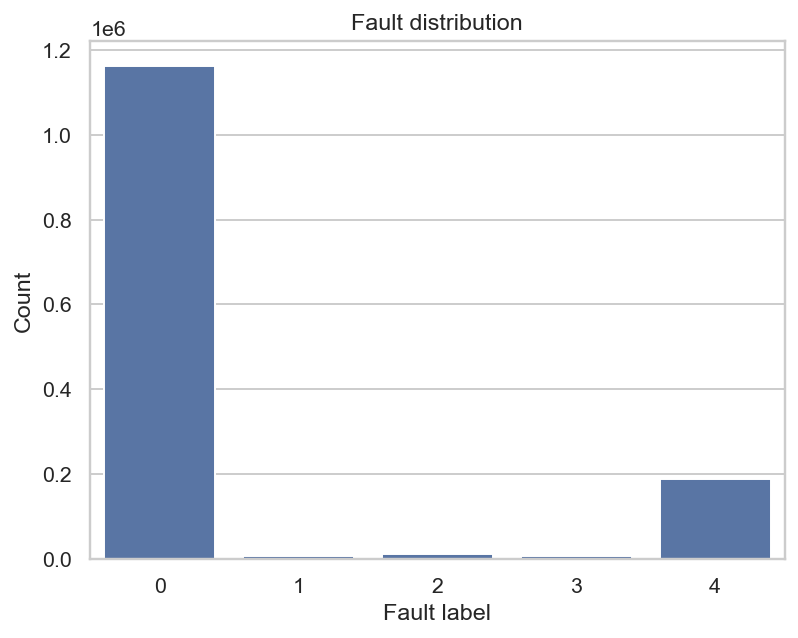

In [8]:
fault_counts = df['fault_label'].value_counts().sort_index()
fault_pct = (fault_counts / len(df)) * 100
print(fault_counts)
print(fault_pct)
sns.countplot(data=df, x='fault_label')
plt.title('Fault distribution')
plt.xlabel('Fault label')
plt.ylabel('Count')
plt.show()

# 11. Statistical Analysis

In [9]:
stats_columns = ['irradiance', 'pv_temperature', 'vdc1', 'vdc2', 'idc1', 'idc2', 'actual_power_w']
df[stats_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
irradiance,1373798.0,257.611072,353.121870,-0.038100,1.290100,1.736400,590.71800,1085.920000
pv_temperature,1373798.0,22.772770,14.231485,-1.654300,12.132700,18.490450,34.15595,60.821500
vdc1,1373798.0,135.118273,136.333921,0.379900,0.890700,37.776250,273.06000,363.974000
vdc2,1373798.0,134.719897,136.730871,0.316400,0.884000,39.837450,271.98600,368.749000
idc1,1373798.0,2.276919,3.190345,0.041800,0.068600,0.113600,5.10210,9.654900
idc2,1373798.0,2.000344,3.038147,0.004600,0.012700,0.044100,4.14040,9.498700
actual_power_w,1373798.0,1139.427800,1653.561229,0.021521,0.090404,5.187949,2466.89263,4944.523249


# 12. Visual Exploration

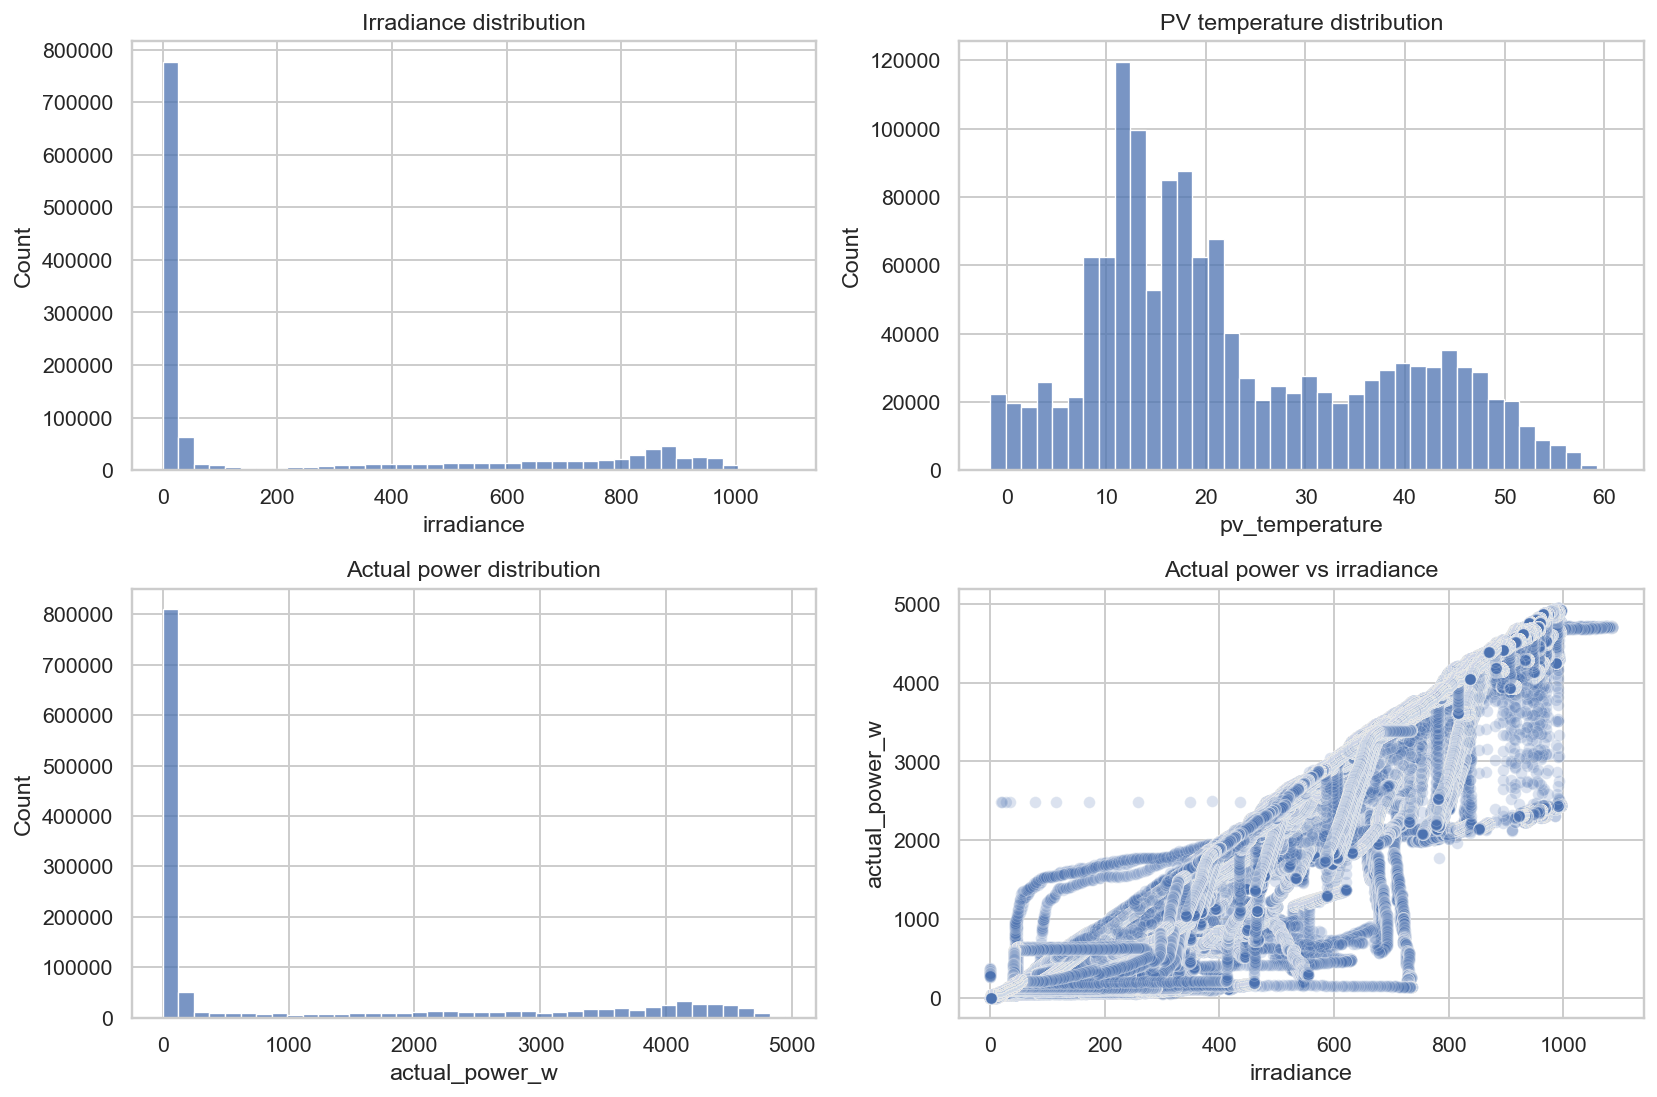

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(df['irradiance'], ax=axes[0, 0], bins=40)
axes[0, 0].set_title('Irradiance distribution')
sns.histplot(df['pv_temperature'], ax=axes[0, 1], bins=40)
axes[0, 1].set_title('PV temperature distribution')
sns.histplot(df['actual_power_w'], ax=axes[1, 0], bins=40)
axes[1, 0].set_title('Actual power distribution')
sns.scatterplot(data=df, x='irradiance', y='actual_power_w', alpha=0.2, ax=axes[1, 1])
axes[1, 1].set_title('Actual power vs irradiance')
plt.tight_layout()
plt.show()

# 13. Findings

The dataset contains the expected electrical and environmental signals. The power calculation is straightforward and aligned with the measured voltage-current pairs. The fault labels are numeric and represent the fault states formally described in the public dataset README.

# 14. Data Preparation Summary

The raw MATLAB files remain untouched. A clean dataframe is created with verified columns, derived power metrics, and explicit validation checks. This prepares the dataset for downstream EDA and later modeling stages.